# DocuLens — 01: Exploratory Data Analysis (NLI Dataset)

This notebook inspects the processed Natural Language Inference (NLI) datasets prepared for training DocuLens in Google Colab.

**Dataset Components:**
1. **MNLI (Multi-Genre NLI)**: General-domain premise-hypothesis sentence pairs.
2. **Domain-Specific Synthetic Policy Pairs**: Company policy / contract pairs covering remote work, payment terms, termination, leave policy, confidentiality, salary, and deadlines.

**Splits Analyzed:**
- `data/processed/train.csv`
- `data/processed/validation.csv`
- `data/processed/test.csv`
- `data/raw/domain_pairs.csv`

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

# Locate data paths
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RAW_DIR = PROJECT_ROOT / "data" / "raw"

print(f"Project root: {PROJECT_ROOT}")
print(f"Processed dir: {PROCESSED_DIR}")

Project root: /Users/abhimanyubishnoi/Desktop/DocuLens
Processed dir: /Users/abhimanyubishnoi/Desktop/DocuLens/data/processed


## 1. Load Processed Datasets

In [2]:
train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
val_df = pd.read_csv(PROCESSED_DIR / "validation.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")
domain_raw_df = pd.read_csv(RAW_DIR / "domain_pairs.csv")

datasets = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df,
}

for name, df in datasets.items():
    print(f"{name:12s} shape: {df.shape[0]:>6,} rows | Columns: {list(df.columns)}")
print(f"{'Domain Raw':12s} shape: {domain_raw_df.shape[0]:>6,} rows | Columns: {list(domain_raw_df.columns)}")

Train        shape: 11,199 rows | Columns: ['premise', 'hypothesis', 'label', 'source']
Validation   shape:    898 rows | Columns: ['premise', 'hypothesis', 'label', 'source']
Test         shape:    899 rows | Columns: ['premise', 'hypothesis', 'label', 'source']
Domain Raw   shape:  2,001 rows | Columns: ['sentence_a', 'sentence_b', 'label']


## 2. Basic Sanity Checks
- Check for missing values (nulls)
- Check for empty string inputs
- Verify label schema adheres strictly to `{"entailment", "neutral", "contradiction"}`

In [3]:
allowed_labels = {"entailment", "neutral", "contradiction"}

sanity_results = []
for name, df in datasets.items():
    null_count = df.isnull().sum().to_dict()
    empty_premise = (df["premise"].astype(str).str.strip() == "").sum()
    empty_hypothesis = (df["hypothesis"].astype(str).str.strip() == "").sum()
    duplicate_pairs = df.duplicated(subset=["premise", "hypothesis"]).sum()
    invalid_labels = (~df["label"].isin(allowed_labels)).sum()
    
    sanity_results.append({
        "Split": name,
        "Total Rows": len(df),
        "Null Values": sum(null_count.values()),
        "Empty Text": empty_premise + empty_hypothesis,
        "Duplicate Pairs": duplicate_pairs,
        "Invalid Labels": invalid_labels
    })

sanity_df = pd.DataFrame(sanity_results)
print("=== SANITY CHECK REPORT ===")
display(sanity_df) if "display" in globals() else print(sanity_df.to_string(index=False))

=== SANITY CHECK REPORT ===
     Split  Total Rows  Null Values  Empty Text  Duplicate Pairs  Invalid Labels
     Train       11199            0           0                0               0
Validation         898            0           0                0               0
      Test         899            0           0                0               0


## 3. Class & Source Distributions

Inspect the distribution of classes across splits and the ratio of domain policy data vs. MNLI general data.

In [4]:
# Class distribution table
class_dist = []
for name, df in datasets.items():
    counts = df["label"].value_counts()
    percents = df["label"].value_counts(normalize=True) * 100
    for lbl in ["entailment", "neutral", "contradiction"]:
        class_dist.append({
            "Split": name,
            "Class": lbl,
            "Count": counts.get(lbl, 0),
            "Percentage": f"{percents.get(lbl, 0.0):.2f}%"
        })

class_dist_df = pd.DataFrame(class_dist)
print("=== CLASS DISTRIBUTION ===")
display(class_dist_df) if "display" in globals() else print(class_dist_df.to_string(index=False))

# Source distribution table
source_dist = []
for name, df in datasets.items():
    counts = df["source"].value_counts()
    percents = df["source"].value_counts(normalize=True) * 100
    for src in ["domain", "mnli"]:
        source_dist.append({
            "Split": name,
            "Source": src,
            "Count": counts.get(src, 0),
            "Percentage": f"{percents.get(src, 0.0):.2f}%"
        })

source_dist_df = pd.DataFrame(source_dist)
print("\n=== SOURCE DISTRIBUTION ===")
display(source_dist_df) if "display" in globals() else print(source_dist_df.to_string(index=False))

=== CLASS DISTRIBUTION ===
     Split         Class  Count Percentage
     Train    entailment   3733     33.33%
     Train       neutral   3733     33.33%
     Train contradiction   3733     33.33%
Validation    entailment    299     33.30%
Validation       neutral    299     33.30%
Validation contradiction    300     33.41%
      Test    entailment    300     33.37%
      Test       neutral    300     33.37%
      Test contradiction    299     33.26%

=== SOURCE DISTRIBUTION ===
     Split Source  Count Percentage
     Train domain   1200     10.72%
     Train   mnli   9999     89.28%
Validation domain    400     44.54%
Validation   mnli    498     55.46%
      Test domain    401     44.61%
      Test   mnli    498     55.39%


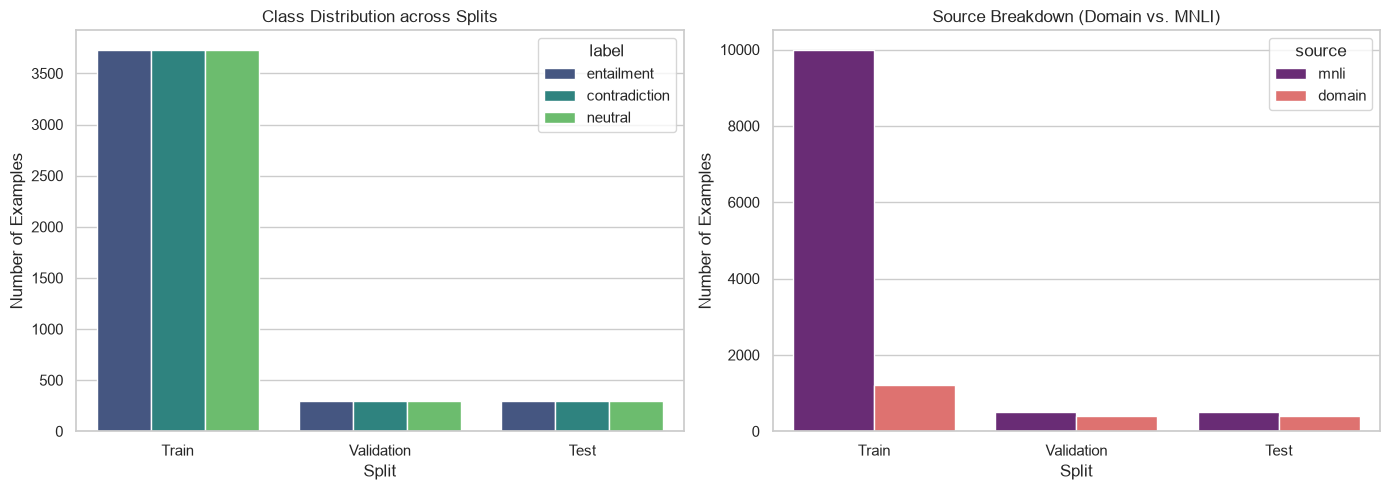

In [5]:
# Plotting Class & Source Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Class Distribution by Split
combined_df = pd.concat([
    df.assign(Split=name) for name, df in datasets.items()
], ignore_index=True)

sns.countplot(data=combined_df, x="Split", hue="label", ax=axes[0], palette="viridis")
axes[0].set_title("Class Distribution across Splits")
axes[0].set_ylabel("Number of Examples")

# Plot 2: Source Distribution by Split
sns.countplot(data=combined_df, x="Split", hue="source", ax=axes[1], palette="magma")
axes[1].set_title("Source Breakdown (Domain vs. MNLI)")
axes[1].set_ylabel("Number of Examples")

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "notebooks" / "class_source_distribution.png", dpi=150)
plt.show()

## 4. Sentence Length Distribution

Analyze word counts and character lengths for premises and hypotheses to evaluate sequence lengths for transformer tokenization.

=== SENTENCE LENGTH SUMMARY (WORD COUNTS) ===
       premise_words  hypothesis_words  total_words
count       12996.00          12996.00     12996.00
mean           19.37             10.49        29.85
std            13.19              4.17        14.94
min             1.00              1.00         2.00
25%            11.00              8.00        20.00
50%            17.00             10.00        28.00
75%            24.00             13.00        36.00
max           231.00             50.00       239.00


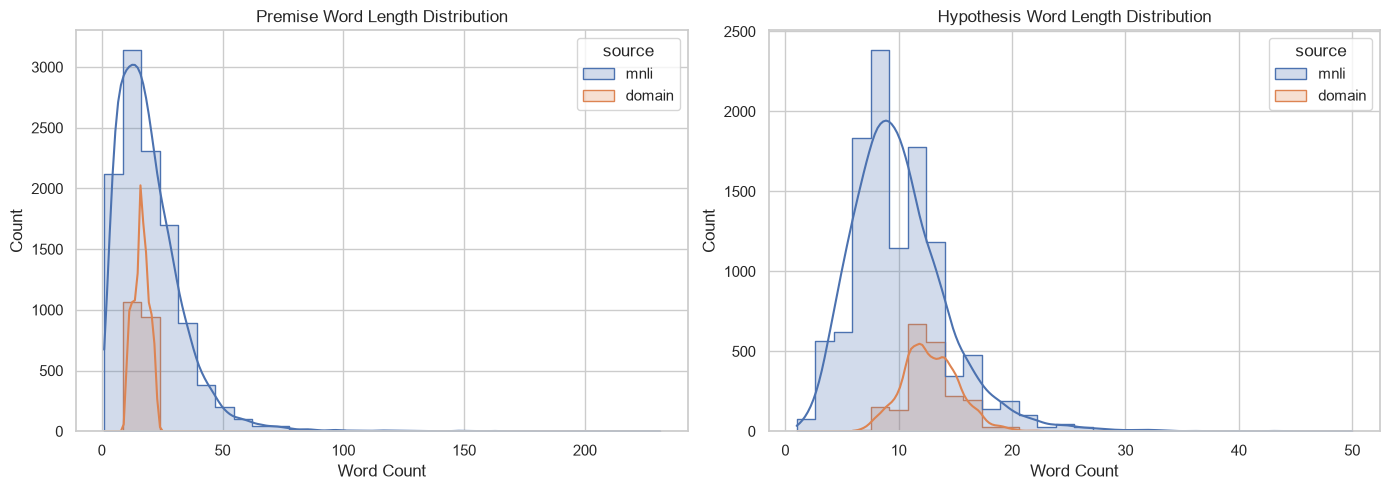

In [6]:
combined_df["premise_words"] = combined_df["premise"].astype(str).apply(lambda x: len(x.split()))
combined_df["hypothesis_words"] = combined_df["hypothesis"].astype(str).apply(lambda x: len(x.split()))
combined_df["total_words"] = combined_df["premise_words"] + combined_df["hypothesis_words"]

print("=== SENTENCE LENGTH SUMMARY (WORD COUNTS) ===")
print(combined_df[["premise_words", "hypothesis_words", "total_words"]].describe().round(2))

# Plot histograms
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=combined_df, x="premise_words", hue="source", kde=True, ax=axes[0], element="step", bins=30)
axes[0].set_title("Premise Word Length Distribution")
axes[0].set_xlabel("Word Count")

sns.histplot(data=combined_df, x="hypothesis_words", hue="source", kde=True, ax=axes[1], element="step", bins=30)
axes[1].set_title("Hypothesis Word Length Distribution")
axes[1].set_xlabel("Word Count")

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "notebooks" / "sentence_length_distribution.png", dpi=150)
plt.show()

## 5. Sample Rows Inspection

Display representative domain-specific policy sentence pairs for each NLI relation.

In [7]:
domain_subset = combined_df[combined_df["source"] == "domain"]

for label in ["entailment", "contradiction", "neutral"]:
    print(f"\n=========================================")
    print(f"Sample pairs for: [{label.upper()}]")
    print(f"=========================================")
    samples = domain_subset[domain_subset["label"] == label].sample(3, random_state=42)
    for idx, row in samples.reset_index().iterrows():
        print(f"Example {idx+1}:")
        print(f"  Premise:    {row['premise']}")
        print(f"  Hypothesis: {row['hypothesis']}")
        print()


Sample pairs for: [ENTAILMENT]
Example 1:
  Premise:    According to the employee handbook, all project milestones must be completed by the dates specified in the project charter.
  Hypothesis: In other words, teams are required to meet the deadlines outlined in the official project plan.

Example 2:
  Premise:    Per the latest company guidelines, the total benefits package, including health, dental, and retirement, equals approximately 30% of base salary.
  Hypothesis: Put simply, employee benefits add roughly a third more to the value of their cash compensation.

Example 3:
  Premise:    Sick leave requires a medical certificate if the absence exceeds three consecutive days.
  Hypothesis: Put simply, employees taking more than three sick days in a row must provide a doctor's note.


Sample pairs for: [CONTRADICTION]
Example 1:
  Premise:    The company policy states that client deliverables have a service level agreement requiring delivery within 48 hours of request.
  Hypothesis: 

## 6. Final Summary of Splits & Classes

In [8]:
summary_matrix = pd.crosstab(
    combined_df["Split"],
    combined_df["label"],
    margins=True,
    margins_name="Total"
)[["entailment", "neutral", "contradiction", "Total"]]

print("\n=======================================================")
print("🎯 FINAL DATASET SUMMARY MATRIX (COUNT PER SPLIT & CLASS)")
print("=======================================================")
print(summary_matrix)
print("\nAll files ready in data/processed/ for Google Colab training!")


🎯 FINAL DATASET SUMMARY MATRIX (COUNT PER SPLIT & CLASS)
label       entailment  neutral  contradiction  Total
Split                                                
Test               300      300            299    899
Train             3733     3733           3733  11199
Validation         299      299            300    898
Total             4332     4332           4332  12996

All files ready in data/processed/ for Google Colab training!
